In [1]:
# Código Corregido
import pandas as pd

df = pd.read_csv(r"C:\Users\Mark\Downloads\vLIFT Digitization and Performance Index - Argentina - Fall 2025_October 29^J 2025_08.44.csv", encoding='latin-1', header=1)

In [2]:
# Selecciona todas las filas EXCEPTO la primera (índice 0)
df = df.iloc[1:]

# Resetea el índice para que comience de 0 de nuevo
df = df.reset_index(drop=True)

In [3]:
def reparar_texto(texto):
    # 1. Ignora cualquier cosa que no sea un string (números, NaN, etc.)
    if not isinstance(texto, str):
        return texto

    try:
        # 2. Intento de "Reparación Doble" (para casos como mÃƒÂ¡s)
        # Repara la corrupción dos veces seguidas
        return texto.encode('latin-1').decode('utf-8').encode('latin-1').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        try:
            # 3. Intento de "Reparación Simple" (para casos como MÃ¡s o Â¿)
            # Repara la corrupción una sola vez
            return texto.encode('latin-1').decode('utf-8')
        except (UnicodeEncodeError, UnicodeDecodeError):
            # 4. Si todo falla, devuelve el texto original
            return texto

In [4]:
def fix_encoding(text):
    # Verifica si el texto es un string antes de intentar arreglarlo
    if isinstance(text, str):
        # El proceso mágico: (string -> bytes) -> (bytes -> string)
        try:
            return text.encode('latin-1').decode('utf-8')
        except (UnicodeEncodeError, UnicodeDecodeError):
            # Si falla (por ejemplo, en un nombre ya correcto), devuelve el original
            return text
    else:
        # Si no es un string (ej. un número), devuélvelo tal cual
        return text

In [5]:
# Esto es lo que debes poner en la Celda 4 (CORREGIDO)
# Asegúrate de haber ejecutado la Celda 8 (que define 'reparar_texto') ANTES que esta.
df.columns = [reparar_texto(col) for col in df.columns]

# ¡Verifica que esta vez sí funcione!
print("--- Columnas Corregidas (con 'reparar_texto') ---")
print(df.columns)

--- Columnas Corregidas (con 'reparar_texto') ---
Index(['Start Date', 'End Date', 'Response Type', 'IP Address', 'Progress',
       'Duration (in seconds)', 'Finished', 'Recorded Date', 'Response ID',
       'Recipient Last Name', 'Recipient First Name', 'Recipient Email',
       'External Data Reference', 'Location Latitude', 'Location Longitude',
       'Distribution Channel', 'User Language', 'Nombre del equipo',
       'Nombre del comercio', 'Nombre completo del Encuestador o Encuestadora',
       'Foto de la fachada del negocio - Id',
       'Foto de la fachada del negocio - Name',
       'Foto de la fachada del negocio - Size',
       'Foto de la fachada del negocio - Type',
       'Foto de la fachada del negocio - URL',
       'Coordenadas del negocio (Latitud, Longitud)', 'Tipo de negocio',
       '¿El negocio tiene reja para entrar? (¿los consumidores pueden entrar a la tienda para escoger y comprar los productos?)',
       '¿Cuál fue el año de apertura del negocio?',
       

In [6]:
# Mal (el código que te di):
# df_corregido = df.applymap(fix_E)

# Bien (el código corregido):
df_corregido = df.applymap(fix_encoding)

# Ahora sí, verifica el resultado:
print("\n--- Datos Corregidos (head) ---")
print(df_corregido.head())


--- Datos Corregidos (head) ---
        Start Date         End Date Response Type IP Address Progress  \
0  10/2/2025 13:38  10/2/2025 14:27    IP Address    *******      100   
1   10/4/2025 6:57   10/4/2025 7:46    IP Address    *******      100   
2   10/4/2025 7:50   10/4/2025 8:06    IP Address    *******      100   
3   10/4/2025 8:08   10/4/2025 8:23    IP Address    *******      100   
4   10/4/2025 8:28   10/4/2025 8:44    IP Address    *******      100   

  Duration (in seconds) Finished    Recorded Date        Response ID  \
0                  2887     TRUE  10/2/2025 14:27  R_1IIdCNJ8zwPVCZb   
1                  2892     TRUE   10/4/2025 7:46  R_6nx4McRsbAx4Hu7   
2                   948     TRUE   10/4/2025 8:06  R_1fHu9kpBWusHc0C   
3                   894     TRUE   10/4/2025 8:23  R_3m2UzzPCRooCx2I   
4                   940     TRUE   10/4/2025 8:44  R_7zvbUlEW6KNAeOH   

  Recipient Last Name  ... Horario de apertura Horario de cierre  \
0             *******  ... 

C:\Users\Mark\AppData\Local\Temp\ipykernel_15868\1398531319.py:5: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_corregido = df.applymap(fix_encoding)


In [7]:
df.head()

,Start Date,End Date,Response Type,IP Address,Progress,Duration (in seconds),Finished,Recorded Date,Response ID,Recipient Last Name,...,Horario de apertura,Horario de cierre,¿Cuál fue el consumo energético del negocio el mes pasado en Kw?,Sexo de la persona encuestada,WhatsApp del la persona entrevistada (Recomendado para la siguiente fase y entrega de reporte final),¿El local de su negocio es rentado o propio?,¿Cuál es el máximo grado de educación de la persona entrevistada?,¿Cuál es la edad de la persona entrevistada?,lat,long
0,10/2/2025 13:38,10/2/2025 14:27,IP Address,*******,100,2887,TRUE,10/2/2025 14:27,R_1IIdCNJ8zwPVCZb,*******,...,9:00 AM,8:30 PM,NaN,Mujer,77124645,Propio,Primaria,MÃÂ¡s de 60,NaN,NaN
1,10/4/2025 6:57,10/4/2025 7:46,IP Address,*******,100,2892,TRUE,10/4/2025 7:46,R_6nx4McRsbAx4Hu7,*******,...,8:30 AM,8:30 PM,1012,Mujer,1150081170,Propio,Universidad y mÃÂ¡s,De 51 a 60,NaN,NaN
2,10/4/2025 7:50,10/4/2025 8:06,IP Address,*******,100,948,TRUE,10/4/2025 8:06,R_1fHu9kpBWusHc0C,*******,...,9:30 AM,7:30 PM,no sabe,Hombre,1132652189,Rentado,Universidad y mÃÂ¡s,MÃÂ¡s de 60,NaN,NaN
3,10/4/2025 8:08,10/4/2025 8:23,IP Address,*******,100,894,TRUE,10/4/2025 8:23,R_3m2UzzPCRooCx2I,*******,...,9:00 AM,8:00 PM,No sabe,Mujer,1126320744,Propio,Secundaria,De 51 a 60,NaN,NaN
4,10/4/2025 8:28,10/4/2025 8:44,IP Address,*******,100,940,TRUE,10/4/2025 8:44,R_7zvbUlEW6KNAeOH,*******,...,8:30 AM,9:00 PM,No lo sabe,Hombre,1126651956,Rentado,Secundaria,De 31 a 40,NaN,NaN


In [8]:
# 'df' es el DataFrame que cargaste (con títulos corruptos)
# y al que le borraste la fila de "ImportId"

# Aplica la nueva función reparadora a CADA celda del DataFrame
df_corregido = df.applymap(reparar_texto)

C:\Users\Mark\AppData\Local\Temp\ipykernel_15868\627162644.py:5: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_corregido = df.applymap(reparar_texto)


In [9]:
# Asumiendo que el título de la columna ya está arreglado a:
# '¿Cuál es el máximo grado de educación de la persona entrevistada?'

# (Si el título de la columna SIGUE corrupto, usa el nombre corrupto aquí)
print(df_corregido['¿Cuál es el máximo grado de educación de la persona entrevistada?'].unique())

['Primaria' 'Universidad y más' 'Secundaria' nan 'Preparatoria'
 'Sin estudios']


In [10]:
df = df_corregido
df

,Start Date,End Date,Response Type,IP Address,Progress,Duration (in seconds),Finished,Recorded Date,Response ID,Recipient Last Name,...,Horario de apertura,Horario de cierre,¿Cuál fue el consumo energético del negocio el mes pasado en Kw?,Sexo de la persona encuestada,WhatsApp del la persona entrevistada (Recomendado para la siguiente fase y entrega de reporte final),¿El local de su negocio es rentado o propio?,¿Cuál es el máximo grado de educación de la persona entrevistada?,¿Cuál es la edad de la persona entrevistada?,lat,long
0,10/2/2025 13:38,10/2/2025 14:27,IP Address,*******,100,2887,TRUE,10/2/2025 14:27,R_1IIdCNJ8zwPVCZb,*******,...,9:00 AM,8:30 PM,NaN,Mujer,77124645,Propio,Primaria,Más de 60,NaN,NaN
1,10/4/2025 6:57,10/4/2025 7:46,IP Address,*******,100,2892,TRUE,10/4/2025 7:46,R_6nx4McRsbAx4Hu7,*******,...,8:30 AM,8:30 PM,1012,Mujer,1150081170,Propio,Universidad y más,De 51 a 60,NaN,NaN
2,10/4/2025 7:50,10/4/2025 8:06,IP Address,*******,100,948,TRUE,10/4/2025 8:06,R_1fHu9kpBWusHc0C,*******,...,9:30 AM,7:30 PM,no sabe,Hombre,1132652189,Rentado,Universidad y más,Más de 60,NaN,NaN
3,10/4/2025 8:08,10/4/2025 8:23,IP Address,*******,100,894,TRUE,10/4/2025 8:23,R_3m2UzzPCRooCx2I,*******,...,9:00 AM,8:00 PM,No sabe,Mujer,1126320744,Propio,Secundaria,De 51 a 60,NaN,NaN
4,10/4/2025 8:28,10/4/2025 8:44,IP Address,*******,100,940,TRUE,10/4/2025 8:44,R_7zvbUlEW6KNAeOH,*******,...,8:30 AM,9:00 PM,No lo sabe,Hombre,1126651956,Rentado,Secundaria,De 31 a 40,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
918,10/21/2025 13:40,10/21/2025 13:47,IP Address,*******,18,458,FALSE,10/28/2025 13:48,R_54GfguJdLQhtdX7,*******,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
919,10/21/2025 13:48,10/21/2025 13:52,IP Address,*******,18,216,FALSE,10/28/2025 13:52,R_5dZ0hy4QrA6KY7U,*******,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
920,10/21/2025 14:08,10/21/2025 14:17,IP Address,*******,0,541,FALSE,10/28/2025 14:18,R_3kjUbREiRSRHi7v,*******,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
921,10/21/2025 14:16,10/21/2025 14:22,IP Address,*******,18,365,FALSE,10/28/2025 14:22,R_6GB89SeZ17h2xqV,*******,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df.isna().sum()

Start Date                                                             0
End Date                                                               0
Response Type                                                          0
IP Address                                                             0
Progress                                                               0
                                                                    ... 
¿El local de su negocio es rentado o propio?                          97
¿Cuál es el máximo grado de educación de la persona entrevistada?    107
¿Cuál es la edad de la persona entrevistada?                          97
lat                                                                  923
long                                                                 923
Length: 66, dtype: int64

In [12]:
print(df.columns)

Index(['Start Date', 'End Date', 'Response Type', 'IP Address', 'Progress',
       'Duration (in seconds)', 'Finished', 'Recorded Date', 'Response ID',
       'Recipient Last Name', 'Recipient First Name', 'Recipient Email',
       'External Data Reference', 'Location Latitude', 'Location Longitude',
       'Distribution Channel', 'User Language', 'Nombre del equipo',
       'Nombre del comercio', 'Nombre completo del Encuestador o Encuestadora',
       'Foto de la fachada del negocio - Id',
       'Foto de la fachada del negocio - Name',
       'Foto de la fachada del negocio - Size',
       'Foto de la fachada del negocio - Type',
       'Foto de la fachada del negocio - URL',
       'Coordenadas del negocio (Latitud, Longitud)', 'Tipo de negocio',
       '¿El negocio tiene reja para entrar? (¿los consumidores pueden entrar a la tienda para escoger y comprar los productos?)',
       '¿Cuál fue el año de apertura del negocio?',
       '¿Cuántas personas trabajaron en este negocio (con

In [13]:
columnas_a_eliminar = [
    'Start Date', 
    'End Date', 
    'Response Type',  # Asumo que 'Status' era esta columna
    'IP Address', 
    'Duration (in seconds)', # Tu 'Duration' se llama así
    'Recipient Last Name', 
    'Recipient First Name', 
    'Recipient Email',
    'External Data Reference', # Tu 'ExternalReference'
    'Location Latitude', 
    'Location Longitude',
    'Distribution Channel', 
    'User Language',
    'Foto de la fachada del negocio - Id',
    'Foto de la fachada del negocio - Name',
    'Foto de la fachada del negocio - Size',
    'Foto de la fachada del negocio - Type',
    'Foto de la fachada del negocio - URL',
    'lat', 
    'long'
]

In [14]:
# Reemplaza 'df_corregido' si tu variable se llama 'df'
df_limpio = df_corregido.drop(columns=columnas_a_eliminar)

In [15]:
print(f"Columnas originales: {len(df_corregido.columns)}")
print(f"Columnas nuevas: {len(df_limpio.columns)}")
print(df_limpio.columns)

Columnas originales: 66
Columnas nuevas: 46
Index(['Progress', 'Finished', 'Recorded Date', 'Response ID',
       'Nombre del equipo', 'Nombre del comercio',
       'Nombre completo del Encuestador o Encuestadora',
       'Coordenadas del negocio (Latitud, Longitud)', 'Tipo de negocio',
       '¿El negocio tiene reja para entrar? (¿los consumidores pueden entrar a la tienda para escoger y comprar los productos?)',
       '¿Cuál fue el año de apertura del negocio?',
       '¿Cuántas personas trabajaron en este negocio (con o sin paga) durante el mes anterior?',
       '¿Cuántas personas trabajaron con un salario fijo durante el último mes?',
       'En tres meses, ¿esperas que el número total de trabajadores del negocio aumente, disminuya o permanezca igual?',
       '¿Tus ventas actuales están mejor, peor o igual en comparación con las de hace un mes?',
       '¿Por qué piensas que las ventas incrementaron/disminuyeron/permanecieron igual? (opcional)',
       '¿Esperas que las ventas d

In [16]:
df = df_limpio 

df = df.drop(columns = ["Nombre del equipo", "Nombre completo del Encuestador o Encuestadora"])

df

,Progress,Finished,Recorded Date,Response ID,Nombre del comercio,"Coordenadas del negocio (Latitud, Longitud)",Tipo de negocio,¿El negocio tiene reja para entrar? (¿los consumidores pueden entrar a la tienda para escoger y comprar los productos?),¿Cuál fue el año de apertura del negocio?,¿Cuántas personas trabajaron en este negocio (con o sin paga) durante el mes anterior?,...,¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una),¿Cuáles de las siguientes tecnologías digitales utilizas actualmente en la operación del negocio? (Marque todas las que correspondan),Horario de apertura,Horario de cierre,¿Cuál fue el consumo energético del negocio el mes pasado en Kw?,Sexo de la persona encuestada,WhatsApp del la persona entrevistada (Recomendado para la siguiente fase y entrega de reporte final),¿El local de su negocio es rentado o propio?,¿Cuál es el máximo grado de educación de la persona entrevistada?,¿Cuál es la edad de la persona entrevistada?
0,100,TRUE,10/2/2025 14:27,R_1IIdCNJ8zwPVCZb,NaN,"34.770292,-58.222781",Almacén,No,1980,1,...,Básico: Usamos al menos una herramienta digita...,Aceptamos pagos electrónicos (ej. billetera mó...,9:00 AM,8:30 PM,NaN,Mujer,77124645,Propio,Primaria,Más de 60
1,100,TRUE,10/4/2025 7:46,R_6nx4McRsbAx4Hu7,NaN,"-34.57749034400566, -58.43047598092801",Pescadería,No,2024,1,...,Alto: La mayoría de nuestras operaciones usan ...,Punto de venta digital (POS) o sistema de inve...,8:30 AM,8:30 PM,1012,Mujer,1150081170,Propio,Universidad y más,De 51 a 60
2,100,TRUE,10/4/2025 8:06,R_1fHu9kpBWusHc0C,NaN,"-34.5770339, -58.4308475",Dietéticas,No,1980,2,...,Moderado: Usamos algunas tecnologías digitales...,Punto de venta digital (POS) o sistema de inve...,9:30 AM,7:30 PM,no sabe,Hombre,1132652189,Rentado,Universidad y más,Más de 60
3,100,TRUE,10/4/2025 8:23,R_3m2UzzPCRooCx2I,NaN,"-34.5770452, -58.4306886",Confitería o Panadería,No,1989,4,...,Moderado: Usamos algunas tecnologías digitales...,Punto de venta digital (POS) o sistema de inve...,9:00 AM,8:00 PM,No sabe,Mujer,1126320744,Propio,Secundaria,De 51 a 60
4,100,TRUE,10/4/2025 8:44,R_7zvbUlEW6KNAeOH,NaN,"-34.5779241, -58.4293843",Almacén,No,2022,5,...,Moderado: Usamos algunas tecnologías digitales...,Aceptamos pagos electrónicos (ej. billetera mó...,8:30 AM,9:00 PM,No lo sabe,Hombre,1126651956,Rentado,Secundaria,De 31 a 40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
918,18,FALSE,10/28/2025 13:48,R_54GfguJdLQhtdX7,Estancia Nilo carnes,"(-34.5362076, -58.4868470)",Carnicería,Sí,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
919,18,FALSE,10/28/2025 13:52,R_5dZ0hy4QrA6KY7U,Verdulería la mejor,"(-34.5358689, -58.4859957)",Verdulería,Sí,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
920,0,FALSE,10/28/2025 14:18,R_3kjUbREiRSRHi7v,Panaderia x,0,Confitería o Panadería,Sí,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
921,18,FALSE,10/28/2025 14:22,R_6GB89SeZ17h2xqV,El carrito de Chipá,"(-34.5943362, -58.3957823)",Confitería o Panadería,No,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
df = df.fillna('Desconocido')

df

,Progress,Finished,Recorded Date,Response ID,Nombre del comercio,"Coordenadas del negocio (Latitud, Longitud)",Tipo de negocio,¿El negocio tiene reja para entrar? (¿los consumidores pueden entrar a la tienda para escoger y comprar los productos?),¿Cuál fue el año de apertura del negocio?,¿Cuántas personas trabajaron en este negocio (con o sin paga) durante el mes anterior?,...,¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una),¿Cuáles de las siguientes tecnologías digitales utilizas actualmente en la operación del negocio? (Marque todas las que correspondan),Horario de apertura,Horario de cierre,¿Cuál fue el consumo energético del negocio el mes pasado en Kw?,Sexo de la persona encuestada,WhatsApp del la persona entrevistada (Recomendado para la siguiente fase y entrega de reporte final),¿El local de su negocio es rentado o propio?,¿Cuál es el máximo grado de educación de la persona entrevistada?,¿Cuál es la edad de la persona entrevistada?
0,100,TRUE,10/2/2025 14:27,R_1IIdCNJ8zwPVCZb,Desconocido,"34.770292,-58.222781",Almacén,No,1980,1,...,Básico: Usamos al menos una herramienta digita...,Aceptamos pagos electrónicos (ej. billetera mó...,9:00 AM,8:30 PM,Desconocido,Mujer,77124645,Propio,Primaria,Más de 60
1,100,TRUE,10/4/2025 7:46,R_6nx4McRsbAx4Hu7,Desconocido,"-34.57749034400566, -58.43047598092801",Pescadería,No,2024,1,...,Alto: La mayoría de nuestras operaciones usan ...,Punto de venta digital (POS) o sistema de inve...,8:30 AM,8:30 PM,1012,Mujer,1150081170,Propio,Universidad y más,De 51 a 60
2,100,TRUE,10/4/2025 8:06,R_1fHu9kpBWusHc0C,Desconocido,"-34.5770339, -58.4308475",Dietéticas,No,1980,2,...,Moderado: Usamos algunas tecnologías digitales...,Punto de venta digital (POS) o sistema de inve...,9:30 AM,7:30 PM,no sabe,Hombre,1132652189,Rentado,Universidad y más,Más de 60
3,100,TRUE,10/4/2025 8:23,R_3m2UzzPCRooCx2I,Desconocido,"-34.5770452, -58.4306886",Confitería o Panadería,No,1989,4,...,Moderado: Usamos algunas tecnologías digitales...,Punto de venta digital (POS) o sistema de inve...,9:00 AM,8:00 PM,No sabe,Mujer,1126320744,Propio,Secundaria,De 51 a 60
4,100,TRUE,10/4/2025 8:44,R_7zvbUlEW6KNAeOH,Desconocido,"-34.5779241, -58.4293843",Almacén,No,2022,5,...,Moderado: Usamos algunas tecnologías digitales...,Aceptamos pagos electrónicos (ej. billetera mó...,8:30 AM,9:00 PM,No lo sabe,Hombre,1126651956,Rentado,Secundaria,De 31 a 40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
918,18,FALSE,10/28/2025 13:48,R_54GfguJdLQhtdX7,Estancia Nilo carnes,"(-34.5362076, -58.4868470)",Carnicería,Sí,Desconocido,Desconocido,...,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido
919,18,FALSE,10/28/2025 13:52,R_5dZ0hy4QrA6KY7U,Verdulería la mejor,"(-34.5358689, -58.4859957)",Verdulería,Sí,Desconocido,Desconocido,...,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido
920,0,FALSE,10/28/2025 14:18,R_3kjUbREiRSRHi7v,Panaderia x,0,Confitería o Panadería,Sí,Desconocido,Desconocido,...,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido
921,18,FALSE,10/28/2025 14:22,R_6GB89SeZ17h2xqV,El carrito de Chipá,"(-34.5943362, -58.3957823)",Confitería o Panadería,No,Desconocido,Desconocido,...,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido,Desconocido


In [18]:
# Obtiene todos los valores únicos de la columna 'Progress'
valores_unicos_progress = df['Progress'].unique()

# Imprime los resultados
print("Los grupos únicos en la columna 'Progress' son:")
print(valores_unicos_progress)

Los grupos únicos en la columna 'Progress' son:
['100' '77' '21' '62' '54' '76' '16' '0' '18' '32' '39' '53' '71']


In [19]:
# Cuenta cuántas veces aparece cada valor único en 'Progress'
# y los ordena del más frecuente al menos frecuente.
conteo_progress = df['Progress'].value_counts()

# Imprime los resultados
print("Conteo de filas por cada grupo de 'Progress':")
print(conteo_progress)

Conteo de filas por cada grupo de 'Progress':
Progress
100    828
0       28
18      21
21      17
76       9
16       5
77       3
54       3
53       3
62       2
39       2
32       1
71       1
Name: count, dtype: int64


In [20]:
import pandas as pd

# 1. Asegurarnos de que la columna 'Progress' es numérica
#    (Por si acaso algún valor se coló como texto)
#    errors='coerce' convierte cualquier texto no numérico en NaN
df['Progress'] = pd.to_numeric(df['Progress'], errors='coerce')

# 2. Guardamos la cantidad de filas ANTES de filtrar
filas_antes = len(df)

# 3. Aplicamos el filtro:
#    Seleccionamos solo las filas donde 'Progress' es mayor que 60
df = df[df['Progress'] > 60]

# 4. Guardamos la cantidad de filas DESPUÉS de filtrar
filas_despues = len(df)

# Imprimimos un resumen
print(f"Filas originales: {filas_antes}")
print(f"Filas eliminadas: {filas_antes - filas_despues}")
print(f"Filas restantes: {filas_despues}")

# Puedes verificar los valores de 'Progress' que quedaron:
print("\nGrupos de 'Progress' que se conservaron:")
print(df['Progress'].value_counts())

Filas originales: 923
Filas eliminadas: 80
Filas restantes: 843

Grupos de 'Progress' que se conservaron:
Progress
100    828
76       9
77       3
62       2
71       1
Name: count, dtype: int64


In [21]:
import numpy as np

def limpiar_coordenadas(coord_str):
    """
    Toma un string de coordenada sucio y lo devuelve
    como (latitud, longitud) numérica y estandarizada.
    """
    # 1. Manejar nulos o tipos no-string
    if pd.isna(coord_str) or not isinstance(coord_str, str):
        return pd.NA, pd.NA

    # 2. Estandarizar el string: quitar paréntesis, espacios
    s = coord_str.strip().replace('(', '').replace(')', '').replace(' ', '')
    
    # 3. Manejar valores basura conocidos
    if s in ['Desconocido', '0', '88888']:
        return pd.NA, pd.NA

    # 4. Dividir por la coma (que ahora es el único separador)
    try:
        lat_str, lon_str = s.split(',')
    except ValueError:
        # No se pudo dividir (ej. "basura" o solo un número)
        return pd.NA, pd.NA

    # 5. Reemplazar comas decimales por puntos (tu requisito)
    #    Maneja "estilo europeo" si existe (ej. "-34,5")
    lat_str = lat_str.replace(',', '.')
    lon_str = lon_str.replace(',', '.')

    # 6. Convertir a número
    try:
        lat = pd.to_numeric(lat_str)
        lon = pd.to_numeric(lon_str)
    except ValueError:
        # La conversión falló (ej. "texto")
        return pd.NA, pd.NA

    # 7. Estandarizar los signos (Argentina = Lat Sur (-), Lon Oeste (-))
    #    Usamos -abs() para asegurar que sean negativos
    lat = -np.abs(lat)
    lon = -np.abs(lon)
    
    return lat, lon

# --- Aplicamos la limpieza ---

# (Asumiendo que tu DataFrame se llama 'df')
col_coordenadas = 'Coordenadas del negocio (Latitud, Longitud)'

print(f"Limpiando y dividiendo la columna: {col_coordenadas}...")

# 1. Aplica la función y divide los resultados en dos nuevas columnas
df[['latitud', 'longitud']] = df[col_coordenadas].apply(limpiar_coordenadas).apply(pd.Series)

# 2. Opcional: Elimina la columna original
df = df.drop(columns=[col_coordenadas])

# 3. Verifica el resultado
print("\n¡Limpieza completa! Así se ven las nuevas columnas:")
print(df[['latitud', 'longitud']].head())

print("\nTipos de datos de las nuevas columnas:")
df[['latitud', 'longitud']].info()

Limpiando y dividiendo la columna: Coordenadas del negocio (Latitud, Longitud)...

¡Limpieza completa! Así se ven las nuevas columnas:
     latitud   longitud
0 -34.770292 -58.222781
1  -34.57749 -58.430476
2 -34.577034 -58.430847
3 -34.577045 -58.430689
4 -34.577924 -58.429384

Tipos de datos de las nuevas columnas:
<class 'pandas.core.frame.DataFrame'>
Index: 843 entries, 0 to 917
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   latitud   722 non-null    object
 1   longitud  722 non-null    object
dtypes: object(2)
memory usage: 19.8+ KB


C:\Users\Mark\AppData\Local\Temp\ipykernel_15868\2458518719.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['latitud', 'longitud']] = df[col_coordenadas].apply(limpiar_coordenadas).apply(pd.Series)
C:\Users\Mark\AppData\Local\Temp\ipykernel_15868\2458518719.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['latitud', 'longitud']] = df[col_coordenadas].apply(limpiar_coordenadas).apply(pd.Series)


In [22]:
df

,Progress,Finished,Recorded Date,Response ID,Nombre del comercio,Tipo de negocio,¿El negocio tiene reja para entrar? (¿los consumidores pueden entrar a la tienda para escoger y comprar los productos?),¿Cuál fue el año de apertura del negocio?,¿Cuántas personas trabajaron en este negocio (con o sin paga) durante el mes anterior?,¿Cuántas personas trabajaron con un salario fijo durante el último mes?,...,Horario de apertura,Horario de cierre,¿Cuál fue el consumo energético del negocio el mes pasado en Kw?,Sexo de la persona encuestada,WhatsApp del la persona entrevistada (Recomendado para la siguiente fase y entrega de reporte final),¿El local de su negocio es rentado o propio?,¿Cuál es el máximo grado de educación de la persona entrevistada?,¿Cuál es la edad de la persona entrevistada?,latitud,longitud
0,100,TRUE,10/2/2025 14:27,R_1IIdCNJ8zwPVCZb,Desconocido,Almacén,No,1980,1,0,...,9:00 AM,8:30 PM,Desconocido,Mujer,77124645,Propio,Primaria,Más de 60,-34.770292,-58.222781
1,100,TRUE,10/4/2025 7:46,R_6nx4McRsbAx4Hu7,Desconocido,Pescadería,No,2024,1,0,...,8:30 AM,8:30 PM,1012,Mujer,1150081170,Propio,Universidad y más,De 51 a 60,-34.57749,-58.430476
2,100,TRUE,10/4/2025 8:06,R_1fHu9kpBWusHc0C,Desconocido,Dietéticas,No,1980,2,0,...,9:30 AM,7:30 PM,no sabe,Hombre,1132652189,Rentado,Universidad y más,Más de 60,-34.577034,-58.430847
3,100,TRUE,10/4/2025 8:23,R_3m2UzzPCRooCx2I,Desconocido,Confitería o Panadería,No,1989,4,4,...,9:00 AM,8:00 PM,No sabe,Mujer,1126320744,Propio,Secundaria,De 51 a 60,-34.577045,-58.430689
4,100,TRUE,10/4/2025 8:44,R_7zvbUlEW6KNAeOH,Desconocido,Almacén,No,2022,5,5,...,8:30 AM,9:00 PM,No lo sabe,Hombre,1126651956,Rentado,Secundaria,De 31 a 40,-34.577924,-58.429384
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
908,100,TRUE,10/28/2025 6:39,R_7U6kdekcXcSPLIB,Atelier Fuerza,Cafeterías,No,2023,3,3,...,9:00 AM,7:00 PM,No sabe,Mujer,1137027531,Rentado,Universidad y más,De 31 a 40,-34.563491,-58.452454
910,100,TRUE,10/28/2025 6:52,R_3Pu3LCPfJU3tlix,El kiosko de Alejo,Kiosko,No,1993,2,2,...,9:00 AM,7:00 PM,No sabe,Hombre,1139464665,Propio,Preparatoria,De 51 a 60,-34.564366,-58.453064
915,100,TRUE,10/28/2025 10:56,R_6OZRCIcyatPqm5I,Donut makers bakery,Cafeterías,No,2025,4,0,...,8:00 AM,8:00 PM,1690 kWh,Mujer,1171167236,Rentado,Universidad y más,De 41 a 50,<NA>,<NA>
916,100,TRUE,10/28/2025 11:19,R_3awtfVIv3lhLU4j,Naymi,Almacén,No,2015,6,6,...,8:00 AM,10:00 PM,3240,Mujer,.,Rentado,Secundaria,De 41 a 50,-34.600912,-58.3741


In [35]:
import os

# Definimos la ruta exacta a tu carpeta de Descargas
# (Usamos la r al principio para evitar problemas con las barras \)
ruta_completa = r"C:\Users\Mark\Downloads\dataset_limpio_final.csv"

df.to_csv(ruta_completa, index=False, encoding='utf-8-sig')

print(f"¡Listo! Archivo guardado en: {ruta_completa}")

¡Listo! Archivo guardado en: C:\Users\Mark\Downloads\dataset_limpio_final.csv


In [23]:
# 1. Define el nombre de la columna que quieres analizar
col_consumo = '¿Cuál fue el consumo energético del negocio el mes pasado en Kw?'

# 2. Usa .value_counts() para obtener los valores únicos y sus conteos
conteo_consumo = df[col_consumo].value_counts()

# 3. Imprime los resultados
print(f"--- Valores Únicos para la Columna: '{col_consumo}' ---")
print(conteo_consumo)

# 4. Opcional: Imprime el número total de valores únicos
print("\n-------------------------------------------------")
print(f"En total, hay {len(conteo_consumo)} valores únicos diferentes en esta columna.")

--- Valores Únicos para la Columna: '¿Cuál fue el consumo energético del negocio el mes pasado en Kw?' ---
¿Cuál fue el consumo energético del negocio el mes pasado en Kw?
Desconocido    170
No sabe         96
-               70
no sabe         21
No sabe         21
              ... 
2757             1
1798             1
1082             1
2600             1
1350             1
Name: count, Length: 353, dtype: int64

-------------------------------------------------
En total, hay 353 valores únicos diferentes en esta columna.


In [24]:
# 1. Define el nombre de la columna que quieres analizar
col_tipo_negocio = 'Tipo de negocio'

# 2. Usa .value_counts() para obtener los valores únicos y sus conteos
conteo_tipos = df[col_tipo_negocio].value_counts()

# 3. Imprime los resultados
print(f"--- Valores Únicos para la Columna: '{col_tipo_negocio}' ---")
print(conteo_tipos)

# 4. Opcional: Imprime el número total de valores únicos
print("\n-------------------------------------------------")
print(f"En total, hay {len(conteo_tipos)} tipos de negocio diferentes.")

--- Valores Únicos para la Columna: 'Tipo de negocio' ---
Tipo de negocio
Almacén                          159
Kiosko                           154
Confitería o Panadería            83
Verdulería                        75
Dietéticas                        74
Carnicería                        61
Bares y pequeños restaurantes     59
Cafeterías                        54
Fiambrería                        46
Granja                            42
Heladería                         14
Pescadería                         9
Cervecería                         5
Huevería                           5
Frutería                           3
Name: count, dtype: int64

-------------------------------------------------
En total, hay 15 tipos de negocio diferentes.


In [25]:
# 1. Define el nombre exacto de la columna
col_adopcion = '¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una)'

# 2. Obtiene el conteo de cada respuesta
conteo_adopcion = df[col_adopcion].value_counts()

# 3. Imprime los resultados
print(f"--- Niveles de Adopción Digital ---")
print(conteo_adopcion)

# 4. (Opcional) Ver el porcentaje que representa cada nivel
print("\n--- Porcentajes ---")
print(df[col_adopcion].value_counts(normalize=True) * 100)

--- Niveles de Adopción Digital ---
¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una)
Moderado: Usamos algunas tecnologías digitales (ej. aceptamos pagos con tarjeta/QR o usamos un sistema POS sencillo o app de pedidos).    491
Alto: La mayoría de nuestras operaciones usan sistemas digitales (ej. software de inventario, caja electrónica, pedidos en línea).        162
Básico: Usamos al menos una herramienta digital básica (ej. un celular o una app de mensajería) para algunas tareas.                      156
Ninguno: No usamos ninguna herramienta digital (todos los procesos son manuales).                                                          24
Desconocido                                                                                                                                10
Name: count, dtype: int64

--- Porcentajes ---
¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una)
Moder

In [26]:
# 1. Define el nombre de la columna
col_adopcion = '¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una)'

# 2. Define la función de limpieza
def limpiar_categoria_digital(texto):
    # Si no es texto (es nulo o número), devolver Desconocido
    if not isinstance(texto, str):
        return "Desconocido"
    
    # Convertir a minúsculas para buscar fácil
    t = texto.lower()
    
    # Buscar palabras clave y devolver la categoría limpia
    if "alto" in t:
        return "Alto"
    elif "moderado" in t:
        return "Moderado"
    elif "básico" in t or "basico" in t:
        return "Básico"
    elif "ninguno" in t:
        return "Ninguno"
    elif "desconocido" in t:
        return "Desconocido"
    else:
        # Si no encuentra ninguna clave, devuelve "Otro" o el texto original
        return "Otro"

# 3. Aplica la función y sobrescribe la columna
df[col_adopcion] = df[col_adopcion].apply(limpiar_categoria_digital)

# 4. Verifica el resultado final
print("--- Categorías Limpias ---")
print(df[col_adopcion].value_counts())

--- Categorías Limpias ---
¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una)
Moderado       491
Alto           162
Básico         156
Ninguno         24
Desconocido     10
Name: count, dtype: int64


C:\Users\Mark\AppData\Local\Temp\ipykernel_15868\1280039334.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


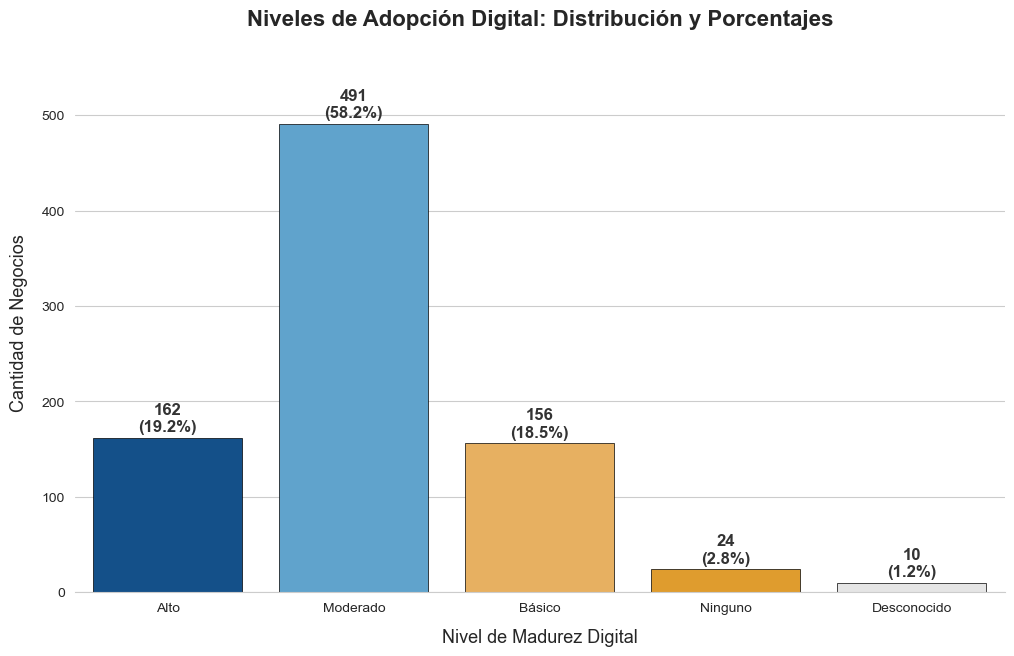

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Configuración
col_adopcion = '¿Cómo describirías el nivel actual de adopción de tecnología digital en su negocio? (Seleccione una)'
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'sans-serif'

# 2. Definir Orden y Colores (Tu paleta complementaria)
orden_categorias = ['Alto', 'Moderado', 'Básico', 'Ninguno', 'Desconocido']
colores_complementarios = {
    'Alto':        '#00509d',
    'Moderado':    '#4ea8de',
    'Básico':      '#fdb44b',
    'Ninguno':     '#fca311',
    'Desconocido': '#e5e5e5',
    'Otro':        '#e5e5e5'
}

# 3. Crear el Gráfico
plt.figure(figsize=(12, 7))
ax = sns.countplot(
    data=df,
    x=col_adopcion,
    order=orden_categorias,
    palette=colores_complementarios,
    edgecolor='black',
    linewidth=0.5
)

# --- 4. AGREGAR ETIQUETAS (CANTIDAD + PORCENTAJE) ---
total = len(df) # Total de datos para calcular el %

for p in ax.patches:
    height = p.get_height()
    # Evitar etiquetas en barras vacías
    if height > 0:
        percentage = (height / total) * 100
        # Crear el texto: "Cantidad" enter "(Porcentaje%)"
        etiqueta = f'{int(height)}\n({percentage:.1f}%)'
        
        ax.annotate(etiqueta, 
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', 
                    fontsize=12, fontweight='bold', color='#333333',
                    xytext=(0, 14), # Subimos un poco más el texto para que quepa el %
                    textcoords='offset points')

# 5. Títulos y Ajustes
plt.title('Niveles de Adopción Digital: Distribución y Porcentajes', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Nivel de Madurez Digital', fontsize=13, labelpad=10)
plt.ylabel('Cantidad de Negocios', fontsize=13, labelpad=10)

# Aumentar el límite superior del eje Y para que quepan las etiquetas nuevas
plt.ylim(0, df[col_adopcion].value_counts().max() * 1.15)

sns.despine(left=True, bottom=False)
plt.show()

C:\Users\Mark\AppData\Local\Temp\ipykernel_15868\4127104030.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


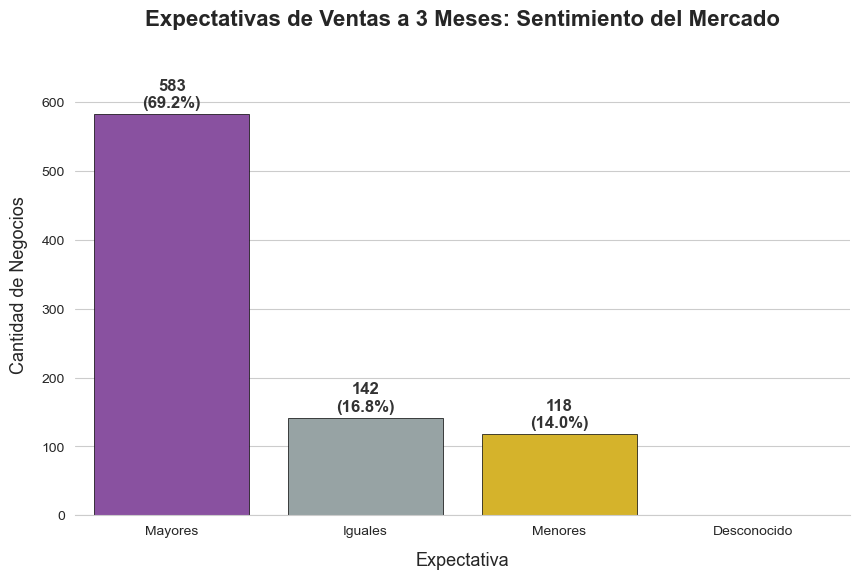

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Configuración
col_expectativas = '¿Esperas que las ventas de tu negocio en tres meses sean mayores, menores o iguales?'
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'sans-serif'

# 2. Definir el Orden Lógico (Positivo -> Neutro -> Negativo)
orden_expectativas = ['Mayores', 'Iguales', 'Menores', 'Desconocido']

# 3. Paleta Complementaria Distinta (Púrpura vs. Amarillo)
# Púrpura: Ambición/Crecimiento (Mayores)
# Amarillo: Precaución/Alerta (Menores)
# Gris: Estabilidad/Neutralidad (Iguales)
colores_sentimiento = {
    'Mayores':     '#8e44ad',  # Púrpura Wisteria (Optimismo fuerte)
    'Iguales':     '#95a5a6',  # Gris Concreto (Neutralidad)
    'Menores':     '#f1c40f',  # Amarillo Girasol (Alerta)
    'Desconocido': '#ecf0f1',  # Gris muy claro
    'Otro':        '#ecf0f1'
}

# 4. Crear el Gráfico
plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=df,
    x=col_expectativas,
    order=orden_expectativas,
    palette=colores_sentimiento,
    edgecolor='black',
    linewidth=0.5
)

# --- 5. Etiquetas con Porcentajes ---
total = len(df)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = (height / total) * 100
        etiqueta = f'{int(height)}\n({percentage:.1f}%)'
        
        ax.annotate(etiqueta, 
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', 
                    fontsize=12, fontweight='bold', color='#333333',
                    xytext=(0, 14),
                    textcoords='offset points')

# 6. Títulos
plt.title('Expectativas de Ventas a 3 Meses: Sentimiento del Mercado', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Expectativa', fontsize=13, labelpad=10)
plt.ylabel('Cantidad de Negocios', fontsize=13, labelpad=10)
plt.ylim(0, df[col_expectativas].value_counts().max() * 1.15)

sns.despine(left=True, bottom=False)
plt.show()

C:\Users\Mark\AppData\Local\Temp\ipykernel_15868\2759330974.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


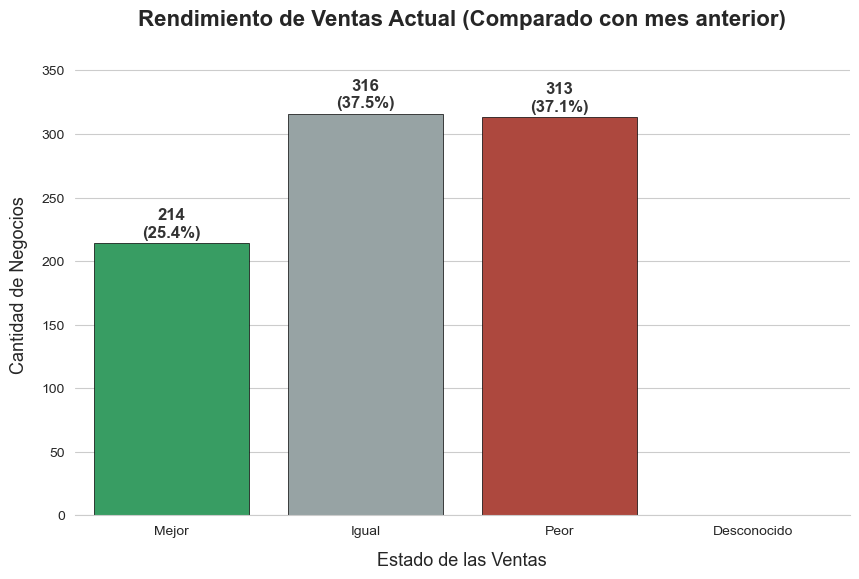

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Configuración
col_ventas_actuales = '¿Tus ventas actuales están mejor, peor o igual en comparación con las de hace un mes?'
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'sans-serif'

# 2. Definir el Orden Lógico (Mejor -> Igual -> Peor)
orden_ventas = ['Mejor', 'Igual', 'Peor', 'Desconocido']

# 3. Paleta Complementaria (Rojo vs. Verde)
# Usamos tonos modernos para que no sea el rojo/verde "chillón" de Excel.
colores_rendimiento = {
    'Mejor':       '#27ae60',  # Verde Esmeralda (Crecimiento sólido)
    'Igual':       '#95a5a6',  # Gris (Estabilidad)
    'Peor':        '#c0392b',  # Rojo Ladrillo (Caída/Pérdida)
    'Desconocido': '#ecf0f1',  # Gris muy claro
    'Otro':        '#ecf0f1'
}

# 4. Crear el Gráfico
plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=df,
    x=col_ventas_actuales,
    order=orden_ventas,
    palette=colores_rendimiento,
    edgecolor='black',
    linewidth=0.5
)

# --- 5. Etiquetas con Porcentajes ---
total = len(df)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = (height / total) * 100
        # Formato: Número arriba, porcentaje abajo
        etiqueta = f'{int(height)}\n({percentage:.1f}%)'
        
        ax.annotate(etiqueta, 
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', 
                    fontsize=12, fontweight='bold', color='#333333',
                    xytext=(0, 14),
                    textcoords='offset points')

# 6. Títulos y Ajustes
plt.title('Rendimiento de Ventas Actual (Comparado con mes anterior)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Estado de las Ventas', fontsize=13, labelpad=10)
plt.ylabel('Cantidad de Negocios', fontsize=13, labelpad=10)

# Margen superior para etiquetas
plt.ylim(0, df[col_ventas_actuales].value_counts().max() * 1.15)

sns.despine(left=True, bottom=False)
plt.show()

C:\Users\Mark\AppData\Local\Temp\ipykernel_15868\911154875.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


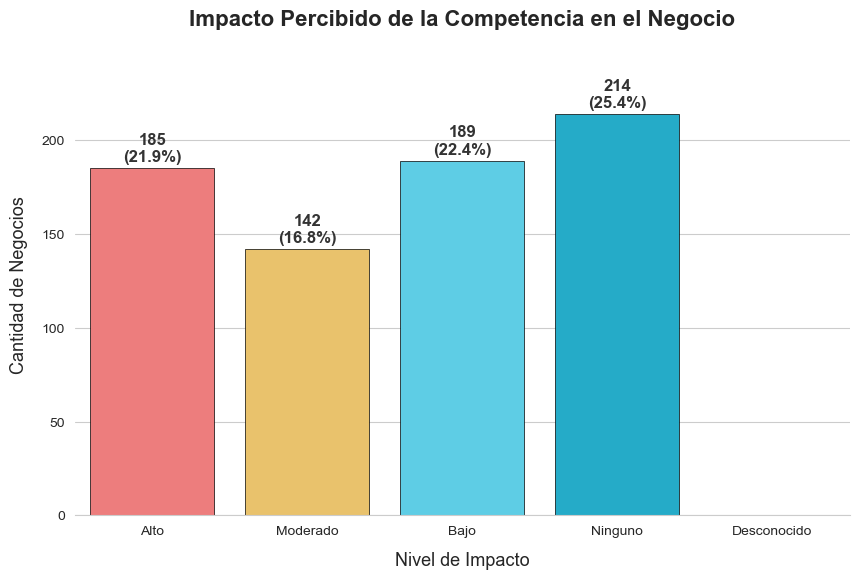

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Configuración
col_competencia = 'Qué tanto impacta a tu negocio: - La competencia'
sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'sans-serif'

# --- 2. Limpieza Rápida (Por si las respuestas son largas) ---
def limpiar_impacto(texto):
    if not isinstance(texto, str):
        return "Desconocido"
    t = texto.lower()
    if "alto" in t or "mucho" in t:
        return "Alto"
    elif "moderado" in t or "medio" in t:
        return "Moderado"
    elif "bajo" in t or "poco" in t:
        return "Bajo"
    elif "ninguno" in t or "nada" in t:
        return "Ninguno"
    elif "desconocido" in t:
        return "Desconocido"
    else:
        return "Otro"

# Aplicamos la limpieza
df[col_competencia] = df[col_competencia].apply(limpiar_impacto)

# 3. Definir Orden y Colores (Coral vs. Turquesa)
orden_impacto = ['Alto', 'Moderado', 'Bajo', 'Ninguno', 'Desconocido']

colores_competencia = {
    'Alto':        '#ff6b6b',  # Coral Intenso (Alerta/Impacto fuerte)
    'Moderado':    '#feca57',  # Amarillo Pastel (Transición)
    'Bajo':        '#48dbfb',  # Turquesa Brillante (Tranquilidad)
    'Ninguno':     '#0abde3',  # Turquesa Profundo (Sin amenaza)
    'Desconocido': '#c8d6e5',  # Gris Azulado
    'Otro':        '#c8d6e5'
}

# 4. Crear el Gráfico
plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=df,
    x=col_competencia,
    order=orden_impacto,
    palette=colores_competencia,
    edgecolor='black',
    linewidth=0.5
)

# --- 5. Etiquetas con Porcentajes ---
total = len(df)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = (height / total) * 100
        etiqueta = f'{int(height)}\n({percentage:.1f}%)'
        
        ax.annotate(etiqueta, 
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', 
                    fontsize=12, fontweight='bold', color='#333333',
                    xytext=(0, 14),
                    textcoords='offset points')

# 6. Títulos
plt.title('Impacto Percibido de la Competencia en el Negocio', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Nivel de Impacto', fontsize=13, labelpad=10)
plt.ylabel('Cantidad de Negocios', fontsize=13, labelpad=10)
plt.ylim(0, df[col_competencia].value_counts().max() * 1.15)

sns.despine(left=True, bottom=False)
plt.show()

In [31]:
import pandas as pd
import numpy as np

# 1. Configuración
col_ano = '¿Cuál fue el año de apertura del negocio?'

# 2. Convertir a numérico (los 'Desconocido' se volverán NaN temporalmente)
#    Esto es necesario para que Pandas pueda saber si 1990 es mayor que 1980.
df['ano_numerico'] = pd.to_numeric(df[col_ano], errors='coerce')

# 3. Definir los Rangos (Bins) y Etiquetas
#    < 1970 | 1970-1979 | 1980-1989 | 1990-1999 | 2000-2009 | 2010-2019 | 2020-Presente
bins = [0, 1969, 1979, 1989, 1999, 2009, 2019, 2030]
labels = ['< 1970', '70s', '80s', '90s', '2000s', '2010s', '2020s']

# 4. Crear la nueva columna 'Decada' usando pd.cut
df['Decada'] = pd.cut(df['ano_numerico'], bins=bins, labels=labels, right=True)

# 5. Recuperar los 'Desconocido'
#    Como pd.cut deja los NaNs como NaN, los volvemos a llamar "Desconocido"
#    Agregamos la categoría 'Desconocido' al tipo de dato 'category' para que no dé error
df['Decada'] = df['Decada'].cat.add_categories(['Desconocido'])
df['Decada'] = df['Decada'].fillna('Desconocido')

# 6. Mostrar la Tabulación
conteo_decadas = df['Decada'].value_counts().sort_index()

print("--- Distribución de Negocios por Década de Apertura ---")
print(conteo_decadas)

# (Opcional) Verificar si quedó algún año suelto
print(f"\nTotal de filas procesadas: {len(df)}")

--- Distribución de Negocios por Década de Apertura ---
Decada
< 1970           0
70s              0
80s             68
90s             57
2000s          118
2010s          219
2020s          381
Desconocido      0
Name: count, dtype: int64

Total de filas procesadas: 843


C:\Users\Mark\AppData\Local\Temp\ipykernel_15868\2555830803.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


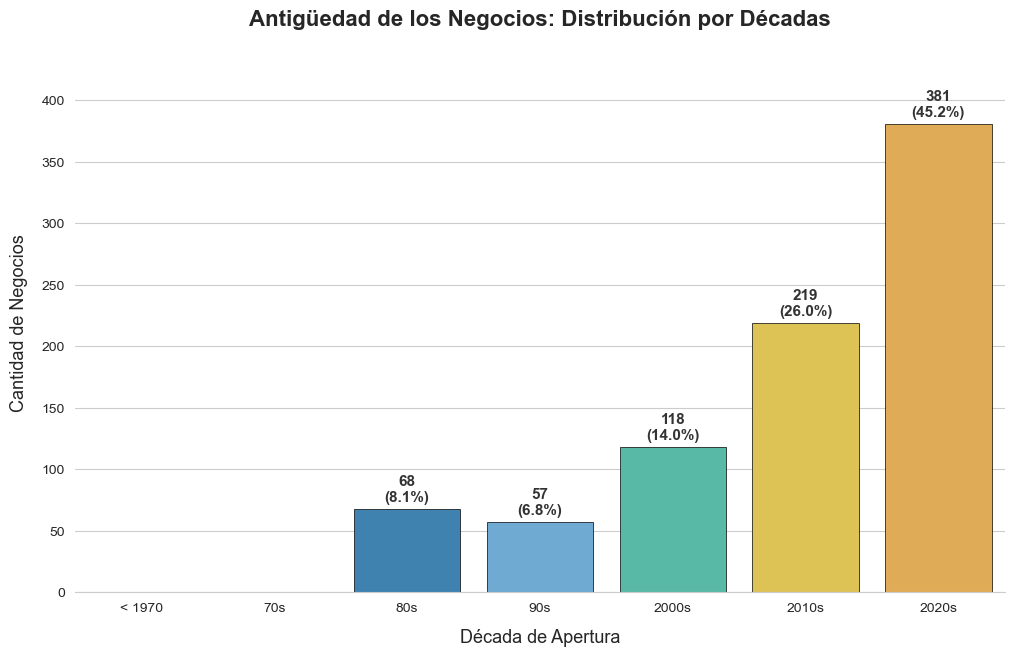

In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Configuración y Filtro
#    Creamos un df temporal que NO tenga los 'Desconocido'
df_grafico = df[df['Decada'] != 'Desconocido'].copy()

sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'sans-serif'

# 2. Definir el Orden Lógico (Cronológico)
orden_decadas = ['< 1970', '70s', '80s', '90s', '2000s', '2010s', '2020s']

# 3. Paleta Secuencial Complementaria (Azul Marino -> Oro)
#    Asignamos un color específico a cada década para crear el efecto degradado.
colores_tiempo = {
    '< 1970': '#0C2D48',  # Azul Marino Profundo (Los más antiguos)
    '70s':    '#145DA0',  # Azul Medio
    '80s':    '#2E86C1',  # Azul Claro
    '90s':    '#5DADE2',  # Celeste
    '2000s':  '#48C9B0',  # Turquesa (Punto medio de transición)
    '2010s':  '#F4D03F',  # Amarillo Oro (Modernidad)
    '2020s':  '#F5B041'   # Naranja Dorado (Lo más reciente)
}

# 4. Crear el Gráfico
plt.figure(figsize=(12, 7))
ax = sns.countplot(
    data=df_grafico,
    x='Decada',
    order=orden_decadas,
    palette=colores_tiempo,
    edgecolor='black',
    linewidth=0.5
)

# --- 5. Etiquetas con Porcentajes ---
total = len(df_grafico) # Calculamos el total sobre los datos filtrados

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = (height / total) * 100
        etiqueta = f'{int(height)}\n({percentage:.1f}%)'
        
        ax.annotate(etiqueta, 
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='center', 
                    fontsize=11, fontweight='bold', color='#333333',
                    xytext=(0, 14),
                    textcoords='offset points')

# 6. Títulos y Ajustes
plt.title('Antigüedad de los Negocios: Distribución por Décadas', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Década de Apertura', fontsize=13, labelpad=10)
plt.ylabel('Cantidad de Negocios', fontsize=13, labelpad=10)

# Ajustar límite superior
if not df_grafico.empty:
    plt.ylim(0, df_grafico['Decada'].value_counts().max() * 1.15)

sns.despine(left=True, bottom=False)
plt.show()